<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QFT Ch 1 Figures — Colab Notebook
**Quantum Field Theory · Chapter 1: Classical Field Theory**

PSE Lab · SeoulTech · Tong (Cambridge)

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Dispersion relation, KG wave packet | §1.2 |
| fig02 | Minkowski light cone, Lorentz boost, invariant hyperbolae | §1.3 |
| fig03 | Noether: energy density, conservation, U(1) charge | §1.4 |
| fig04 | $\phi^4$ & Mexican hat potentials, Hamiltonian density | §1.5 |

---
## fig01 · Dispersion Relation & Wave Packet (§1.2)

**Left**: Relativistic dispersion $E=\sqrt{k^2+m^2}$ vs massless and NR approx. **Centre**: KG plane waves. **Right**: Gaussian wave packet — $v_g=k/\omega<c$, $v_p=\omega/k>c$.

  saved -> figures/ch01/fig01_dispersion.png


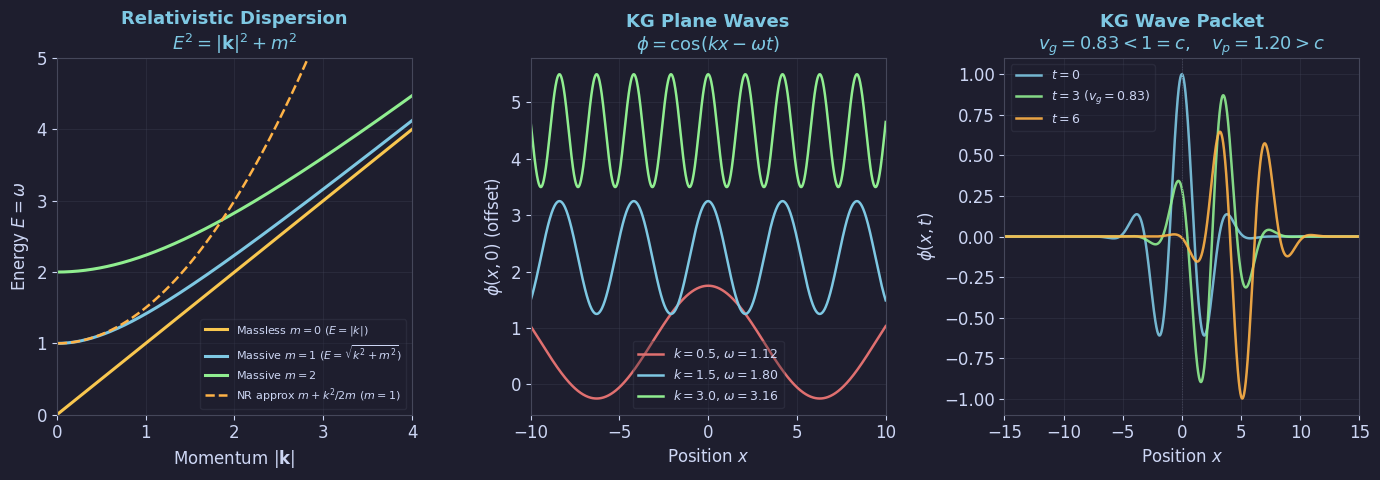

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch01'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig01: Dispersion relation + wave packet ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

k = np.linspace(0, 4, 300)
ax = axes[0]
for m, col, lab in [
    (0, YELLOW, r'Massless $m=0$ ($E=|k|$)'),
    (1, BLUE,   r'Massive $m=1$ ($E=\sqrt{k^2+m^2}$)'),
    (2, GREEN,  r'Massive $m=2$'),
]:
    ax.plot(k, np.sqrt(k**2 + m**2), color=col, lw=2.2, label=lab)
k_nr = np.linspace(0.01, 4, 200)
ax.plot(k_nr, 1 + k_nr**2/2, color=ORANGE, lw=1.8, ls='--',
        label=r'NR approx $m+k^2/2m$ ($m=1$)')
ax.set_xlabel(r'Momentum $|\mathbf{k}|$')
ax.set_ylabel(r'Energy $E=\omega$')
ax.set_title('Relativistic Dispersion\n' + r'$E^2=|\mathbf{k}|^2+m^2$', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 4); ax.set_ylim(0, 5)

ax2 = axes[1]
x = np.linspace(-10, 10, 1000)
for k0, col, lab in [(0.5, RED, '$k=0.5$'), (1.5, BLUE, '$k=1.5$'), (3.0, GREEN, '$k=3.0$')]:
    m_val = 1.0; omega = np.sqrt(k0**2 + m_val**2)
    ax2.plot(x, np.cos(k0*x) + k0*1.5, color=col, lw=1.8,
             label=f'$k={k0},\\,\\omega={omega:.2f}$')
ax2.set_xlabel('Position $x$')
ax2.set_ylabel(r'$\phi(x,0)$ (offset)')
ax2.set_title('KG Plane Waves\n' + r'$\phi=\cos(kx-\omega t)$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True); ax2.set_xlim(-10, 10)

ax3 = axes[2]
x = np.linspace(-15, 15, 2000)
sigma = 2.0; k0 = 1.5; m_val = 1.0
omega0 = np.sqrt(k0**2 + m_val**2)
vg = k0/omega0; vp = omega0/k0
for t_val, col, lab in [
    (0, BLUE,   '$t=0$'),
    (3, GREEN,  f'$t=3$ ($v_g={vg:.2f}$)'),
    (6, ORANGE, '$t=6$'),
]:
    x0 = vg * t_val
    envelope = np.exp(-(x - x0)**2 / (2*sigma**2))
    ax3.plot(x, envelope * np.cos(k0*(x - vp*t_val)), color=col, lw=1.8, label=lab, alpha=0.9)
ax3.axvline(0, color=EDGE, lw=0.7, ls=':')
ax3.set_xlabel('Position $x$')
ax3.set_ylabel(r'$\phi(x,t)$')
ax3.set_title(f'KG Wave Packet\n$v_g={vg:.2f}<1=c,\\quad v_p={vp:.2f}>c$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True); ax3.set_xlim(-15, 15)

plt.tight_layout(pad=1.2)
save('fig01_dispersion.png', fig)


---
## fig02 · Light Cone & Lorentz Boost (§1.3)

**Left**: Minkowski light cone — timelike/spacelike/lightlike. **Centre**: Lorentz boost for rapidity $\eta=0,0.3,0.6,0.9$. **Right**: Invariant hyperbolae $t^2-x^2=\tau^2$.

  saved -> figures/ch01/fig02_lightcone.png


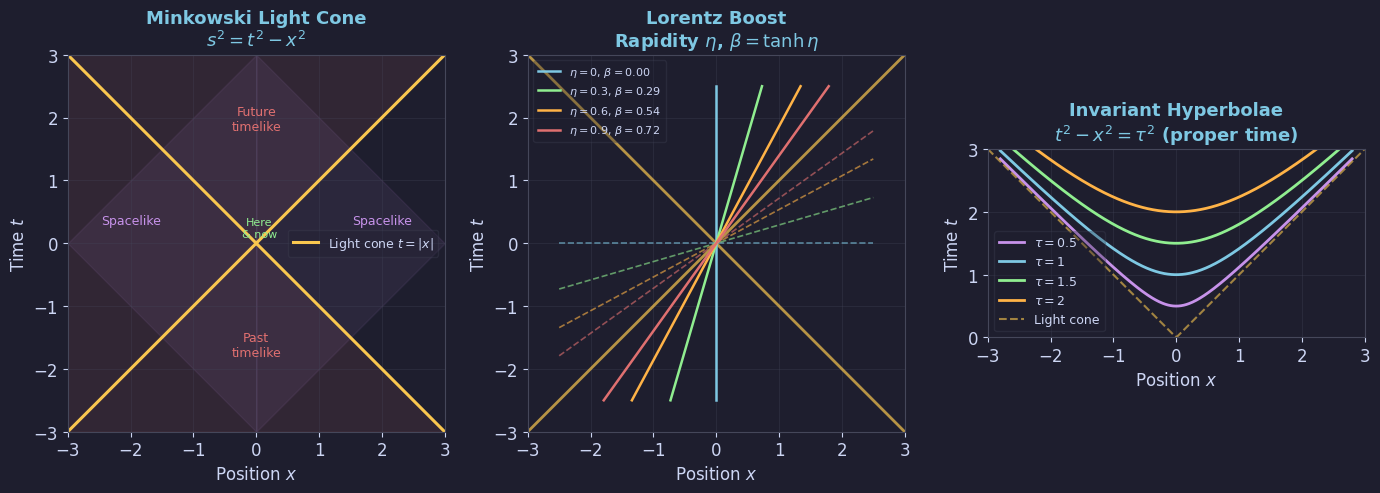

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch01'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig02: Light cone + Lorentz boost ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
t_lc = np.linspace(-3, 3, 200)
ax.fill_between(t_lc,  t_lc,  3,           color=RED,    alpha=0.10)
ax.fill_between(t_lc, -3,    -abs(t_lc),   color=RED,    alpha=0.10)
ax.fill_between([-3, 0], [0,  3], [0, -3], color=PURPLE, alpha=0.08)
ax.fill_between([ 0, 3], [3,  0], [-3, 0], color=PURPLE, alpha=0.08)
ax.plot(t_lc,  abs(t_lc), color=YELLOW, lw=2.2, label=r'Light cone $t=|x|$')
ax.plot(t_lc, -abs(t_lc), color=YELLOW, lw=2.2)
ax.text( 0.0,  1.8, 'Future\ntimelike', ha='center', color=RED,    fontsize=9)
ax.text( 0.0, -1.8, 'Past\ntimelike',   ha='center', color=RED,    fontsize=9)
ax.text( 2.0,  0.3, 'Spacelike',        ha='center', color=PURPLE, fontsize=9)
ax.text(-2.0,  0.3, 'Spacelike',        ha='center', color=PURPLE, fontsize=9)
ax.text( 0.05, 0.1, 'Here\n& now',      ha='center', color=GREEN,  fontsize=8)
ax.set_xlabel('Position $x$'); ax.set_ylabel('Time $t$')
ax.set_title('Minkowski Light Cone\n' + r'$s^2=t^2-x^2$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect('equal')

ax2 = axes[1]
x_arr = np.linspace(-3, 3, 200)
ax2.plot(x_arr,  abs(x_arr), color=YELLOW, lw=2.0, alpha=0.7)
ax2.plot(x_arr, -abs(x_arr), color=YELLOW, lw=2.0, alpha=0.7)
for eta, col in zip([0, 0.3, 0.6, 0.9], [BLUE, GREEN, ORANGE, RED]):
    beta = np.tanh(eta)
    t_line = np.linspace(-2.5, 2.5, 100)
    ax2.plot(beta*t_line, t_line, color=col, lw=1.8,
             label=f'$\\eta={eta}$, $\\beta={beta:.2f}$')
    ax2.plot(np.linspace(-2.5, 2.5, 100),
             beta*np.linspace(-2.5, 2.5, 100), color=col, lw=1.2, ls='--', alpha=0.6)
ax2.set_xlabel('Position $x$'); ax2.set_ylabel('Time $t$')
ax2.set_title('Lorentz Boost\n' + r'Rapidity $\eta$, $\beta=\tanh\eta$', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(-3, 3); ax2.set_ylim(-3, 3); ax2.set_aspect('equal')

ax3 = axes[2]
x_hyp = np.linspace(-2.8, 2.8, 400)
for tau, col, lab in [
    (0.5, PURPLE, r'$\tau=0.5$'), (1.0, BLUE,   r'$\tau=1$'),
    (1.5, GREEN,  r'$\tau=1.5$'), (2.0, ORANGE, r'$\tau=2$'),
]:
    t_hyp = np.sqrt(tau**2 + x_hyp**2)
    mask = t_hyp <= 3
    ax3.plot(x_hyp[mask], t_hyp[mask], color=col, lw=2.0, label=lab)
ax3.plot(x_arr, abs(x_arr), color=YELLOW, lw=1.5, ls='--', alpha=0.6, label='Light cone')
ax3.set_xlabel('Position $x$'); ax3.set_ylabel('Time $t$')
ax3.set_title('Invariant Hyperbolae\n' + r'$t^2-x^2=\tau^2$ (proper time)', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(-3, 3); ax3.set_ylim(0, 3); ax3.set_aspect('equal')

plt.tight_layout(pad=1.2)
save('fig02_lightcone.png', fig)


---
## fig03 · Noether Theorem (§1.4)

**Left**: Energy density $T^{00}$ of KG wave packet. **Centre**: Total energy $E=\int T^{00}d^3x$ conserved. **Right**: U(1) charge density $j^0$.

  saved -> figures/ch01/fig03_noether.png


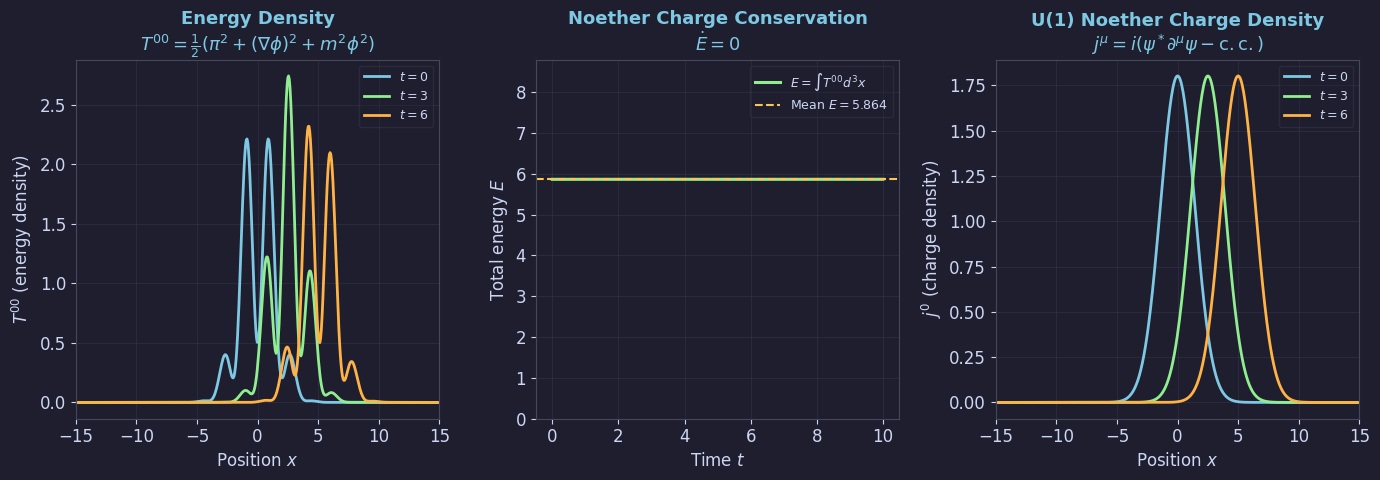

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch01'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig03: Noether — energy density + U(1) charge ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

x = np.linspace(-15, 15, 500)
sigma = 2.0; k0 = 1.5; m_val = 1.0
omega0 = np.sqrt(k0**2 + m_val**2); vg = k0/omega0

ax = axes[0]
for t_val, col, lab in [(0, BLUE, '$t=0$'), (3, GREEN, '$t=3$'), (6, ORANGE, '$t=6$')]:
    x0   = vg * t_val
    phi  = np.exp(-(x - x0)**2 / (2*sigma**2)) * np.cos(k0*x - omega0*t_val)
    pi_f = -omega0 * np.exp(-(x - x0)**2 / (2*sigma**2)) * np.sin(k0*x - omega0*t_val)
    dphi = np.gradient(phi, x)
    T00  = 0.5*pi_f**2 + 0.5*dphi**2 + 0.5*m_val**2*phi**2
    ax.plot(x, T00, color=col, lw=2.0, label=lab)
ax.set_xlabel('Position $x$')
ax.set_ylabel(r'$T^{00}$ (energy density)')
ax.set_title('Energy Density\n' + r'$T^{00}=\frac{1}{2}(\pi^2+(\nabla\phi)^2+m^2\phi^2)$',
             color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True); ax.set_xlim(-15, 15)

ax2 = axes[1]
t_arr = np.linspace(0, 10, 100)
E_arr = []
for t_val in t_arr:
    x0   = vg * t_val
    phi  = np.exp(-(x - x0)**2 / (2*sigma**2)) * np.cos(k0*x - omega0*t_val)
    pi_f = -omega0 * np.exp(-(x - x0)**2 / (2*sigma**2)) * np.sin(k0*x - omega0*t_val)
    dphi = np.gradient(phi, x)
    T00  = 0.5*pi_f**2 + 0.5*dphi**2 + 0.5*m_val**2*phi**2
    E_arr.append(np.trapezoid(T00, x))
E_mean = float(np.mean(E_arr))
ax2.plot(t_arr, E_arr, color=GREEN, lw=2.2, label=r'$E=\int T^{00}d^3x$')
ax2.axhline(E_mean, color=YELLOW, lw=1.5, ls='--', label=f'Mean $E={E_mean:.3f}$')
ax2.set_xlabel('Time $t$'); ax2.set_ylabel('Total energy $E$')
ax2.set_title('Noether Charge Conservation\n' + r'$\dot{E}=0$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_ylim(0, max(E_arr)*1.5)

ax3 = axes[2]
for t_val, col, lab in [(0, BLUE, '$t=0$'), (3, GREEN, '$t=3$'), (6, ORANGE, '$t=6$')]:
    x0  = vg * t_val
    env = np.exp(-(x - x0)**2 / (2*sigma**2))
    ax3.plot(x, omega0 * env**2, color=col, lw=2.0, label=lab)
ax3.set_xlabel('Position $x$')
ax3.set_ylabel(r'$j^0$ (charge density)')
ax3.set_title('U(1) Noether Charge Density\n' + r'$j^\mu=i(\psi^*\partial^\mu\psi-\mathrm{c.c.})$',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True); ax3.set_xlim(-15, 15)

plt.tight_layout(pad=1.2)
save('fig03_noether.png', fig)


---
## fig04 · Potentials & Hamiltonian Density (§1.5)

**Left**: $\phi^4$ potential — single minimum. **Centre**: Mexican hat — degenerate vacuum circle (SSB). **Right**: $\mathcal{H}$ in $(\phi,\pi)$ phase space.

  saved -> figures/ch01/fig04_potential.png


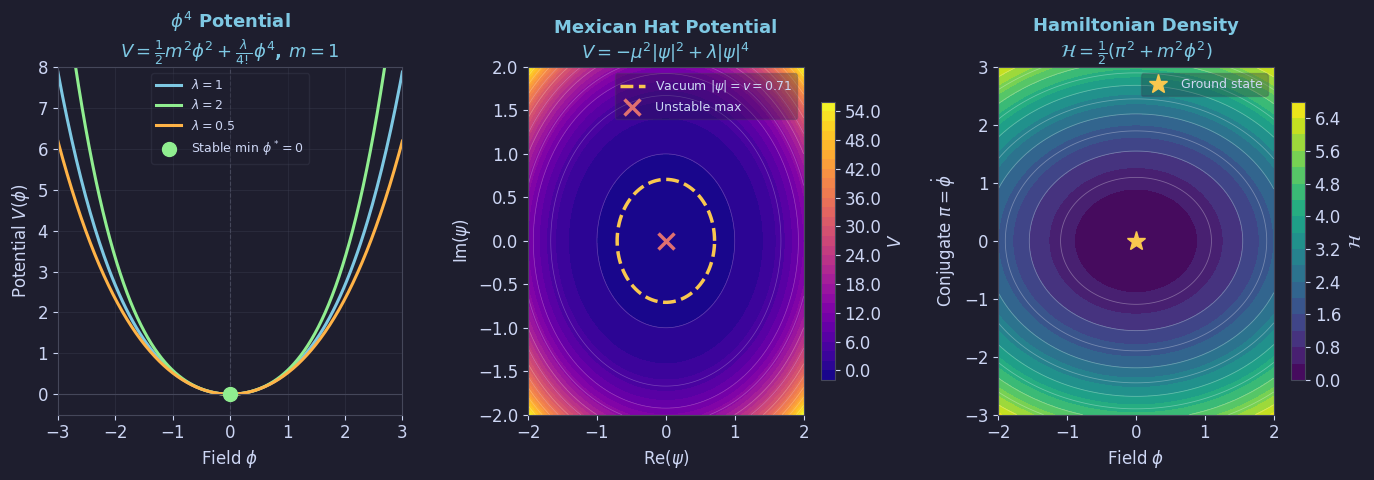

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch01'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig04: Potentials + Hamiltonian ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

phi_arr = np.linspace(-3, 3, 300)
ax = axes[0]
for lam, col in [(1, BLUE), (2, GREEN), (0.5, ORANGE)]:
    V = 0.5*phi_arr**2 + (lam/24)*phi_arr**4
    ax.plot(phi_arr, V, color=col, lw=2.2, label=f'$\\lambda={lam}$')
ax.axvline(0, color=EDGE, lw=0.8, ls='--')
ax.axhline(0, color=EDGE, lw=0.8)
ax.plot([0], [0], 'o', color=GREEN, ms=10, zorder=5,
        label=r'Stable min $\phi^*=0$')
ax.set_xlabel(r'Field $\phi$'); ax.set_ylabel(r'Potential $V(\phi)$')
ax.set_title(r'$\phi^4$ Potential' + '\n'
             + r'$V=\frac{1}{2}m^2\phi^2+\frac{\lambda}{4!}\phi^4$, $m=1$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-3, 3); ax.set_ylim(-0.5, 8)

phi1 = np.linspace(-2, 2, 200); phi2 = np.linspace(-2, 2, 200)
P1, P2 = np.meshgrid(phi1, phi2)
mu2 = 1.0; lam_h = 1.0
V_hat = -mu2*(P1**2 + P2**2) + lam_h*(P1**2 + P2**2)**2
v = np.sqrt(mu2 / (2*lam_h))
ax2 = axes[1]
cf = ax2.contourf(P1, P2, V_hat, levels=30, cmap='plasma')
ax2.contour(P1, P2, V_hat, levels=12, colors='white', alpha=0.25, linewidths=0.5)
theta_arr = np.linspace(0, 2*np.pi, 200)
ax2.plot(v*np.cos(theta_arr), v*np.sin(theta_arr), color=YELLOW, lw=2.5, ls='--',
         label=f'Vacuum $|\\psi|=v={v:.2f}$')
ax2.plot([0], [0], 'x', color=RED, ms=12, mew=2.5, label='Unstable max')
ax2.set_xlabel(r'$\mathrm{Re}(\psi)$'); ax2.set_ylabel(r'$\mathrm{Im}(\psi)$')
ax2.set_title('Mexican Hat Potential\n' + r'$V=-\mu^2|\psi|^2+\lambda|\psi|^4$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG)
fig.colorbar(cf, ax=ax2, shrink=0.8, label='$V$', format='%.1f')

phi_h = np.linspace(-2, 2, 100); pi_h = np.linspace(-3, 3, 100)
PHI, PI = np.meshgrid(phi_h, pi_h)
H_dens = 0.5*PI**2 + 0.5*PHI**2
ax3 = axes[2]
cf3 = ax3.contourf(PHI, PI, H_dens, levels=20, cmap='viridis')
ax3.contour(PHI, PI, H_dens, levels=10, colors='white', alpha=0.3, linewidths=0.6)
ax3.plot([0], [0], '*', color=YELLOW, ms=14, zorder=5, label='Ground state')
ax3.set_xlabel(r'Field $\phi$'); ax3.set_ylabel(r'Conjugate $\pi=\dot\phi$')
ax3.set_title('Hamiltonian Density\n' + r'$\mathcal{H}=\frac{1}{2}(\pi^2+m^2\phi^2)$',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)
fig.colorbar(cf3, ax=ax3, shrink=0.8, label=r'$\mathcal{H}$')

plt.tight_layout(pad=1.2)
save('fig04_potential.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

# AUTO-INJECTED: Korean font setup for matplotlib
import os as _os
import matplotlib.font_manager as _fm
import matplotlib.pyplot as _plt
if not any('NanumGothic' in f.name for f in _fm.fontManager.ttflist):
    for _font in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
                  '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf']:
        if _os.path.exists(_font):
            _fm.fontManager.addfont(_font)
_plt.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False})
del _os, _fm, _plt
# END AUTO-INJECTED Korean font setup


OUTDIR = 'figures/ch01'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')])
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'qft_ch01_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 4 figures:
  fig01_dispersion.png  (293 KB)
  fig02_lightcone.png  (224 KB)
  fig03_noether.png  (197 KB)
  fig04_potential.png  (383 KB)
Zip: qft_ch01_figures.zip  (1064 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>